# 02 — Plus de flexibilité aide-t-elle ?

**Question :** des arbres font-ils mieux que le meilleur modèle linéaire du notebook 01 (PDQ + mois + t + t², MAE 5,99) ?
Le modèle linéaire donne la même tendance à tous les PDQ : il sous-estime les gros postes.
Un arbre peut apprendre une tendance différente par PDQ, mais il risque d'apprendre le train par cœur.

On compare sur la **validation (2023)** : l'erreur moyenne, les grosses erreurs (p90), l'erreur sur les **5 plus gros PDQ**
et l'écart entre train et validation. Le **test reste fermé** jusqu'au choix final.

**Contrat (v1, inchangé) :** pour chaque PDQ actif, avant le début de la semaine, estimer les actes déclarés de la semaine,
à partir du calendrier seulement (PDQ, mois, temps écoulé).

In [1]:
import json
import hashlib
import tomllib
from pathlib import Path
import pandas as pd

ROOT = Path.cwd().parent
with open(ROOT / "configs/crimes.toml", "rb") as f:
    cfg = tomllib.load(f)

SEED = cfg["experiment"]["seed"]
DATA_PATH = ROOT / cfg["data"]["path"]
IN = ROOT / "artifacts" / "00_start_here"

panel = pd.read_parquet(IN / "panel.parquet")
meta = json.loads((IN / "meta.json").read_text())
meta_01 = json.loads((ROOT / "artifacts" / "01_regression_lineaire" / "meta.json").read_text())

empreinte = hashlib.sha256(DATA_PATH.read_bytes()).hexdigest()[:16]
assert empreinte == meta["source_sha16"], "Le CSV a changé depuis le notebook 00 : relance le 00 d'abord."
assert meta_01["source_sha16"] == meta["source_sha16"], "Le notebook 01 a été fait sur d'autres données : relance le 01."

panel["t"] = (panel["SEMAINE"] - panel["SEMAINE"].min()).dt.days / 365.25
panel["t2"] = panel["t"] ** 2
panel["mois"] = panel["SEMAINE"].dt.month

print("Panel :", panel.shape)
print("À battre (notebook 01) :", meta_01["modele_retenu"], "| MAE validation", meta_01["mae_validation"])

Panel : (17835, 7)
À battre (notebook 01) : pdq_mois_t_t2 | MAE validation 5.993


## Choix fixés avant d'entraîner
Métrique principale : MAE. Tranche de décision : les 5 PDQ les plus chargés du **train**,
là où une erreur coûte le plus en effectifs, et là où le modèle linéaire sous-estime.
Elle est choisie **avant** de voir les résultats des arbres, pour ne pas choisir la tranche qui arrange.

In [2]:
METRIQUE = "mae"

moyennes_pdq = panel[panel["ENSEMBLE"] == "train"].groupby("PDQ")["y"].mean()
GROS_PDQ = moyennes_pdq.nlargest(5).index.tolist()

print("Tranche de décision (5 plus gros PDQ du train) :", GROS_PDQ)
moyennes_pdq.loc[GROS_PDQ].round(1)

Tranche de décision (5 plus gros PDQ du train) : ['38', '21', '20', '48', '39']


PDQ
38    41.1
21    34.0
20    32.5
48    28.1
39    26.5
Name: y, dtype: float64

## Outil d'évaluation
Même fonction que le notebook 01, avec trois mesures de plus :
- `p90_erreur` : 90 % des erreurs sont plus petites que cette valeur (la taille des grosses erreurs) ;
- `mae_gros_pdq` : l'erreur moyenne sur les 5 plus gros PDQ ;
- `biais_gros_pdq` : la moyenne de l'erreur avec son signe sur ces PDQ (positif = sous-estimés).

In [3]:
from sklearn.pipeline import make_pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.metrics import mean_absolute_error, root_mean_squared_error

train = panel[panel["ENSEMBLE"] == "train"]
validation = panel[panel["ENSEMBLE"] == "validation"]
# Pas de variable « test » : il reste fermé jusqu'à la fin du notebook.

modeles = {}
resultats = []

def evaluer(nom, estimateur, numeriques=(), categorielles=()):
    colonnes = list(numeriques) + list(categorielles)

    # 1. Préparation des colonnes (identique au notebook 01)
    etapes = []
    if numeriques:
        etapes.append(("num", StandardScaler(), list(numeriques)))
    if categorielles:
        etapes.append(("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), list(categorielles)))

    # 2. Entraînement sur le TRAIN seulement
    modele = make_pipeline(ColumnTransformer(etapes), estimateur)
    modele.fit(train[colonnes], train["y"])

    # 3. Prédictions et erreurs
    pred_validation = modele.predict(validation[colonnes])
    pred_train = modele.predict(train[colonnes])
    erreur = validation["y"] - pred_validation
    gros = validation["PDQ"].isin(GROS_PDQ)

    modeles[nom] = modele
    resultats.append({
        "modele": nom,
        "mae_validation": mean_absolute_error(validation["y"], pred_validation),
        "rmse_validation": root_mean_squared_error(validation["y"], pred_validation),
        "mae_train": mean_absolute_error(train["y"], pred_train),
        "p90_erreur": erreur.abs().quantile(0.9),
        "mae_gros_pdq": erreur[gros].abs().mean(),
        "biais_gros_pdq": erreur[gros].mean(),
    })
    return pd.DataFrame(resultats).set_index("modele").round(3)

## Références
On refait la constante et le meilleur modèle linéaire du notebook 01, avec la même fonction, pour comparer les arbres à armes égales.

In [4]:
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression

evaluer("moyenne", DummyRegressor(strategy="mean"), numeriques=["t"])
evaluer("mediane", DummyRegressor(strategy="median"), numeriques=["t"])
evaluer("lineaire_t2", LinearRegression(), numeriques=["t", "t2"], categorielles=["PDQ", "mois"])

,mae_validation,rmse_validation,mae_train,p90_erreur,mae_gros_pdq,biais_gros_pdq
modele,,,,,,
moyenne,9.796,13.647,8.612,21.356,21.652,21.563
mediane,9.971,14.171,8.456,23.000,23.254,23.208
lineaire_t2,5.993,7.972,4.987,12.392,8.828,4.538


## Un arbre peu profond
Au plus 5 questions (32 feuilles), au moins 10 semaines par feuille.
Hypothèse : en posant des questions sur le PDQ **puis** sur le temps, l'arbre peut donner une tendance différente aux gros PDQ.

In [5]:
from sklearn.tree import DecisionTreeRegressor

evaluer("arbre_court", DecisionTreeRegressor(max_depth=5, min_samples_leaf=10, random_state=SEED),
        numeriques=["t"], categorielles=["PDQ", "mois"])

,mae_validation,rmse_validation,mae_train,p90_erreur,mae_gros_pdq,biais_gros_pdq
modele,,,,,,
moyenne,9.796,13.647,8.612,21.356,21.652,21.563
mediane,9.971,14.171,8.456,23.000,23.254,23.208
lineaire_t2,5.993,7.972,4.987,12.392,8.828,4.538
arbre_court,7.403,9.780,6.655,16.318,9.646,2.422


## Un arbre sans limite
Aucune limite de profondeur, et une feuille peut ne contenir qu'une seule semaine.
Prédiction à vérifier : que deviennent l'erreur sur le train et l'erreur sur la validation ?

In [6]:
evaluer("arbre_profond", DecisionTreeRegressor(max_depth=None, min_samples_leaf=1, random_state=SEED),
        numeriques=["t"], categorielles=["PDQ", "mois"])

,mae_validation,rmse_validation,mae_train,p90_erreur,mae_gros_pdq,biais_gros_pdq
modele,,,,,,
moyenne,9.796,13.647,8.612,21.356,21.652,21.563
mediane,9.971,14.171,8.456,23.000,23.254,23.208
lineaire_t2,5.993,7.972,4.987,12.392,8.828,4.538
arbre_court,7.403,9.780,6.655,16.318,9.646,2.422
arbre_profond,6.620,8.801,0.000,14.000,9.712,3.227


## Une forêt : la moyenne de 100 arbres
Chaque arbre apprend sur un tirage au hasard des semaines du train ; la forêt fait la moyenne de leurs prédictions.
Les erreurs propres à chaque arbre se compensent en partie.

In [7]:
from sklearn.ensemble import RandomForestRegressor

evaluer("foret", RandomForestRegressor(n_estimators=100, max_depth=12, min_samples_leaf=3,
                                       max_features=1.0, random_state=SEED, n_jobs=1),
        numeriques=["t"], categorielles=["PDQ", "mois"])

,mae_validation,rmse_validation,mae_train,p90_erreur,mae_gros_pdq,biais_gros_pdq
modele,,,,,,
moyenne,9.796,13.647,8.612,21.356,21.652,21.563
mediane,9.971,14.171,8.456,23.000,23.254,23.208
lineaire_t2,5.993,7.972,4.987,12.392,8.828,4.538
arbre_court,7.403,9.780,6.655,16.318,9.646,2.422
arbre_profond,6.620,8.801,0.000,14.000,9.712,3.227
foret,6.012,8.263,4.950,13.553,9.158,4.982


## Le boosting : des petits arbres qui corrigent les erreurs des précédents
Un premier petit arbre prédit ; le suivant apprend ses erreurs ; le suivant apprend les erreurs restantes, etc.
Chaque arbre ne corrige qu'une petite part (8 %) de ce qui reste, en 120 étapes.

In [8]:
from sklearn.ensemble import HistGradientBoostingRegressor

evaluer("boosting", HistGradientBoostingRegressor(max_iter=120, max_leaf_nodes=15, learning_rate=0.08,
                                                  min_samples_leaf=20, early_stopping=False, random_state=SEED),
        numeriques=["t"], categorielles=["PDQ", "mois"])

,mae_validation,rmse_validation,mae_train,p90_erreur,mae_gros_pdq,biais_gros_pdq
modele,,,,,,
moyenne,9.796,13.647,8.612,21.356,21.652,21.563
mediane,9.971,14.171,8.456,23.000,23.254,23.208
lineaire_t2,5.993,7.972,4.987,12.392,8.828,4.538
arbre_court,7.403,9.780,6.655,16.318,9.646,2.422
arbre_profond,6.620,8.801,0.000,14.000,9.712,3.227
foret,6.012,8.263,4.950,13.553,9.158,4.982
boosting,5.170,7.145,4.313,11.402,7.813,3.674


## Écart entre train et validation
Un grand écart signale un modèle qui a appris le train par cœur.

In [9]:
ecarts = pd.DataFrame(resultats).set_index("modele")[["mae_train", "mae_validation"]]
ecarts["ecart"] = ecarts["mae_validation"] - ecarts["mae_train"]
ecarts.round(3)

,mae_train,mae_validation,ecart
modele,,,
moyenne,8.612,9.796,1.184
mediane,8.456,9.971,1.515
lineaire_t2,4.987,5.993,1.006
arbre_court,6.655,7.403,0.748
arbre_profond,0.000,6.620,6.620
foret,4.950,6.012,1.062
boosting,4.313,5.170,0.857


**Constat — Flexibilité.** Un arbre court (7,40) est trop grossier : 32 feuilles pour 29 PDQ, les mois et les années.
Sans limite, l'arbre apprend le train par cœur (MAE train 0,00) et reste moins bon que le linéaire en validation (6,62).
La forêt égale le linéaire (6,01) sans corriger les gros PDQ (biais +5,0).
Le **boosting** est le meilleur sur toutes les mesures : MAE 5,17, p90 11,4, MAE gros PDQ 7,8, avec un petit écart train/validation (0,86).
Il réduit le biais des gros PDQ (+3,7 contre +4,5) sans le supprimer.

## La profondeur seule
On change **une seule chose** : le nombre de questions (5, 8, 12), avec toujours au moins 10 semaines par feuille.
L'arbre profond de tout à l'heure changeait deux réglages à la fois (profondeur ET taille des feuilles) : on ne savait pas lequel jouait.

In [10]:
for profondeur in [8, 12]:
    tableau = evaluer(f"arbre_p{profondeur}", DecisionTreeRegressor(max_depth=profondeur, min_samples_leaf=10, random_state=SEED),
                      numeriques=["t"], categorielles=["PDQ", "mois"])
tableau.loc[["arbre_court", "arbre_p8", "arbre_p12", "lineaire_t2"]]

,mae_validation,rmse_validation,mae_train,p90_erreur,mae_gros_pdq,biais_gros_pdq
modele,,,,,,
arbre_court,7.403,9.780,6.655,16.318,9.646,2.422
arbre_p8,6.656,9.187,5.900,15.870,8.402,0.816
arbre_p12,6.052,8.183,5.191,13.569,8.657,1.414
lineaire_t2,5.993,7.972,4.987,12.392,8.828,4.538


## `t²` sert-il à un arbre ?
Pour un arbre, « t > 7 ? » et « t² > 49 ? » coupent les semaines au même endroit. Hypothèse : ajouter t² ne change rien.

In [11]:
evaluer("boosting_t2", HistGradientBoostingRegressor(max_iter=120, max_leaf_nodes=15, learning_rate=0.08,
                                                     min_samples_leaf=20, early_stopping=False, random_state=SEED),
        numeriques=["t", "t2"], categorielles=["PDQ", "mois"]).loc[["boosting", "boosting_t2"]]

,mae_validation,rmse_validation,mae_train,p90_erreur,mae_gros_pdq,biais_gros_pdq
modele,,,,,,
boosting,5.17,7.145,4.313,11.402,7.813,3.674
boosting_t2,5.17,7.145,4.313,11.402,7.813,3.674


## Que prédisent les modèles après l'entraînement ?
On calcule les prédictions jusqu'en 2026 **à partir du calendrier seulement** (PDQ, mois, t) :
la colonne `y` du test n'est pas utilisée, le test reste fermé.

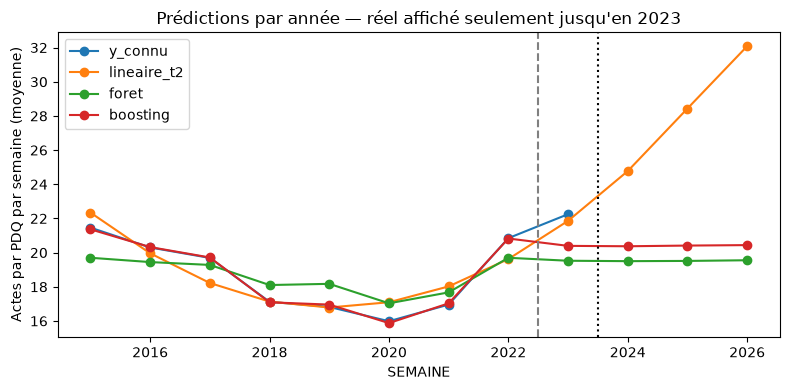

,y_connu,lineaire_t2,foret,boosting
SEMAINE,,,,
2015,21.5,22.3,19.7,21.4
2016,20.3,20.0,19.4,20.3
2017,19.7,18.2,19.3,19.7
2018,17.1,17.1,18.1,17.1
2019,16.8,16.8,18.2,17.0
2020,16.0,17.1,17.0,15.9
2021,17.0,18.0,17.7,17.0
2022,20.8,19.6,19.7,20.8
2023,22.2,21.9,19.5,20.4


In [12]:
import matplotlib.pyplot as plt

calendrier = panel[["SEMAINE", "PDQ", "t", "t2", "mois", "ENSEMBLE"]].copy()   # PAS la colonne y
for nom in ["lineaire_t2", "foret", "boosting"]:
    m = modeles[nom]
    calendrier[nom] = m.predict(calendrier[list(m.feature_names_in_)])

prevu = calendrier.groupby(calendrier["SEMAINE"].dt.year)[["lineaire_t2", "foret", "boosting"]].mean()
reel_connu = panel[panel["ENSEMBLE"] != "test"].groupby(panel["SEMAINE"].dt.year)["y"].mean()
prevu.insert(0, "y_connu", reel_connu)

ax = prevu.plot(marker="o", figsize=(8, 4))
ax.axvline(2022.5, color="grey", linestyle="--")
ax.axvline(2023.5, color="black", linestyle=":")
ax.set_ylabel("Actes par PDQ par semaine (moyenne)")
ax.set_title("Prédictions par année — réel affiché seulement jusqu'en 2023")
plt.tight_layout()
plt.show()
prevu.round(1)

## Choix du modèle (figé avant le test)
Règle fixée d'avance : la plus petite MAE sur la validation.

In [13]:
tableau = pd.DataFrame(resultats).set_index("modele")
choix = tableau["mae_validation"].idxmin()
lineaire = tableau.loc["lineaire_t2", "mae_validation"]
reference = tableau.loc["moyenne", "mae_validation"]
mae_choix = tableau.loc[choix, "mae_validation"]

print("Modèle retenu :", choix)
print(f"MAE validation : {mae_choix:.3f} | linéaire : {lineaire:.3f} | moyenne : {reference:.3f}")
print(f"Gain sur le linéaire : {lineaire - mae_choix:.2f} actes ({(lineaire - mae_choix) / lineaire:.0%})")
print(f"Gain sur la moyenne : {reference - mae_choix:.2f} actes ({(reference - mae_choix) / reference:.0%})")

Modèle retenu : boosting
MAE validation : 5.170 | linéaire : 5.993 | moyenne : 9.796
Gain sur le linéaire : 0.82 actes (14%)
Gain sur la moyenne : 4.63 actes (47%)


**Constat — Choix.** Le boosting est retenu : MAE validation 5,17, soit 0,82 acte de moins que le linéaire (−14 %) et 4,63 de moins que la constante (−47 %).
Il est aussi le meilleur sur les grosses erreurs (p90 11,4) et sur les 5 plus gros PDQ (MAE 7,8).
Un arbre seul ne bat pas le linéaire, quelle que soit sa profondeur ; `t²` n'apporte rien aux arbres.
Après l'entraînement, les arbres prolongent le dernier niveau connu (≈ 20 actes) au lieu d'une parabole qui s'emballe.

**Décision figée :** on ouvrira le test une seule fois, pour trois modèles : la constante (moyenne), le linéaire du notebook 01 et le boosting.
Aucun modèle ne sera modifié après avoir vu le test.

## Ouverture du test (une seule fois)
Les trois modèles annoncés sont évalués sur 2024 → octobre 2026, des semaines jamais utilisées pour entraîner ni pour choisir.

In [14]:
test = panel[panel["ENSEMBLE"] == "test"]
print("Test :", test["SEMAINE"].min().date(), "→", test["SEMAINE"].max().date(), "|", len(test), "lignes")

lignes_test = []
for nom in ["moyenne", "lineaire_t2", choix]:
    m = modeles[nom]
    pred = m.predict(test[list(m.feature_names_in_)])
    erreur = test["y"] - pred
    gros = test["PDQ"].isin(GROS_PDQ)
    lignes_test.append({
        "modele": nom,
        "mae_test": mean_absolute_error(test["y"], pred),
        "rmse_test": root_mean_squared_error(test["y"], pred),
        "p90_erreur": erreur.abs().quantile(0.9),
        "mae_gros_pdq": erreur[gros].abs().mean(),
        "biais": erreur.mean(),
    })
resultats_test = pd.DataFrame(lignes_test).set_index("modele")
resultats_test.round(3)

Test : 2024-01-01 → 2026-10-12 | 4234 lignes


,mae_test,rmse_test,p90_erreur,mae_gros_pdq,biais
modele,,,,,
moyenne,9.565,13.334,18.356,19.858,1.393
lineaire_t2,10.333,12.181,18.895,11.963,-8.094
boosting,5.191,7.188,10.344,8.710,-0.368


## Où le modèle retenu se trompe-t-il sur le test ?
Diagnostic seulement : le modèle n'est pas modifié.

In [15]:
m = modeles[choix]
diag = test.copy()
diag["erreur"] = diag["y"] - m.predict(diag[list(m.feature_names_in_)])

par_annee_test = diag.groupby(diag["SEMAINE"].dt.year)["erreur"].agg(
    biais="mean",
    mae=lambda e: e.abs().mean(),
)
par_pdq_test = diag.groupby("PDQ")["erreur"].mean().sort_values(ascending=False)

display(par_annee_test.round(2))
par_pdq_test.head(3).round(2)

,biais,mae
SEMAINE,,
2024,0.42,4.94
2025,-0.73,5.27
2026,-0.92,5.42


PDQ
21    13.67
15     5.46
26     3.25
Name: erreur, dtype: float64

## Sauvegarde
Le modèle retenu (avec la preuve qu'on le relit à l'identique), les tableaux de résultats et la fiche `meta.json`.

In [16]:
import joblib
import numpy as np

OUT = ROOT / "artifacts" / "02_arbres"
OUT.mkdir(parents=True, exist_ok=True)

# Le modèle, puis la preuve qu'on le relit à l'identique
joblib.dump(modeles[choix], OUT / "modele.joblib")
relu = joblib.load(OUT / "modele.joblib")
X_verif = test[list(relu.feature_names_in_)].head(10)
np.testing.assert_allclose(relu.predict(X_verif), modeles[choix].predict(X_verif))

# Les preuves
tableau.round(3).to_csv(OUT / "resultats_validation.csv")
ecarts.round(3).to_csv(OUT / "ecarts.csv")
prevu.round(2).to_csv(OUT / "predictions_par_annee.csv")
resultats_test.round(3).to_csv(OUT / "resultats_test.csv")
par_pdq_test.round(2).to_csv(OUT / "biais_test_par_pdq.csv")

meta_02 = {
    "source_sha16": meta["source_sha16"],
    "contrat": meta_01["contrat"],
    "metrique": METRIQUE,
    "tranche_decision": GROS_PDQ,
    "choix_sur": "validation",
    "modele_retenu": choix,
    "colonnes": list(modeles[choix].feature_names_in_),
    "parametres": {k: v for k, v in modeles[choix][-1].get_params().items() if k in
                   ["max_iter", "max_leaf_nodes", "learning_rate", "min_samples_leaf", "early_stopping", "random_state"]},
    "mae_validation": round(float(mae_choix), 3),
    "mae_test": round(float(resultats_test.loc[choix, "mae_test"]), 3),
    "mae_test_moyenne": round(float(resultats_test.loc["moyenne", "mae_test"]), 3),
    "mae_test_lineaire": round(float(resultats_test.loc["lineaire_t2", "mae_test"]), 3),
    "test_regarde": True,
    "modifie_apres_test": False,
}
(OUT / "meta.json").write_text(json.dumps(meta_02, indent=2, ensure_ascii=False))
sorted(p.name for p in OUT.iterdir())

['biais_test_par_pdq.csv',
 'ecarts.csv',
 'meta.json',
 'modele.joblib',
 'predictions_par_annee.csv',
 'resultats_test.csv',
 'resultats_validation.csv']

## Résumé

| Modèle | MAE validation (2023) | MAE test (2024 → 2026) |
|---|---|---|
| Constante (moyenne) | 9,80 | 9,57 |
| Linéaire PDQ + mois + t + t² (notebook 01) | 5,99 | **10,33** |
| **Boosting PDQ + mois + t** | **5,17** | **5,19** |

**Ce qu'on retient.**
- Le boosting se trompe en moyenne de **5,2 actes par PDQ-semaine** sur près de trois ans jamais vus, contre 9,6 pour la constante (**−46 %**).
  Son erreur de test est presque égale à celle de validation : le choix était fiable.
- Le linéaire, meilleur que la constante en 2023, devient **pire** qu'elle sur le test (biais −8,1) : la parabole `t²` s'emballe dès qu'on s'éloigne de l'entraînement.
- Un arbre seul ne bat pas le linéaire ; la flexibilité paie quand on combine beaucoup de petits arbres qui se corrigent (boosting).
- Après l'entraînement, les arbres prolongent le dernier niveau connu au lieu d'inventer une tendance : c'est plus prudent.

**Limites connues.**
- **Niveau figé :** le boosting prolonge le niveau de fin 2022. Si la criminalité change durablement, il ne le verra pas ; l'erreur grandit déjà d'année en année (4,9 → 5,3 → 5,4). Il faut le réentraîner régulièrement.
- **Fermeture du PDQ 22 :** le PDQ 21 est sous-estimé de 13,7 actes par semaine sur le test, car son territoire s'est agrandi fin 2024.
- **Gros PDQ :** ils restent sous-estimés (biais +3,7 en validation).
- **Calendrier seulement :** le modèle ne connaît pas les semaines récentes. Le notebook 03 ajoutera les semaines passées, en respectant la latence de déclaration de 14 jours.